# Argo study -- geometric analysis using data depth

This notebook demonstrates how we can use the concept of [data depth](https://arxiv.org/abs/1207.4988) to identify central and outlying points in the [Argo](https://globalocean.noaa.gov/research/argo-program/) data.

Quite a bit of processing is needed to prepare the data for these analyses.  You should review the [get_data.py](https://github.com/kshedden/case_studies/blob/main/argo/get_data.py), [prep.py](https://github.com/kshedden/case_studies/blob/main/argo/prep.py), and [read.py](https://github.com/kshedden/case_studies/blob/main/argo/read.py) scripts to understand how this is done.

In [15]:
import numpy as np
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from statsmodels.nonparametric.smoothers_lowess import lowess
import pandas as pd
from read import *

The temperature profiles are in the columns of the array 'temp', and the salinity profiles are in the columns of the array 'psal'.  Each profile is a vector of 100 values, corresponding to the pressures in the vector 'pressure'.

In [16]:
print(temp.shape)
print(psal.shape)

(100, 49583)
(100, 49583)


The mean temperature and pressure are plotted below.  These marginal means are not very informative about the overall distribution of the data.

Text(0, 0.5, 'Mean temperature (C)')

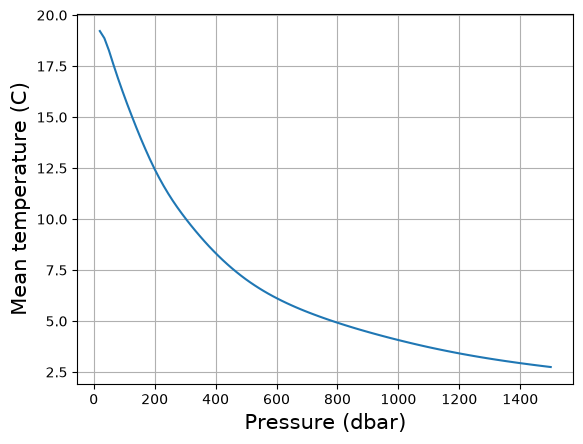

In [17]:
plt.clf()
plt.grid(True)
plt.plot(pressure, temp.mean(1))
plt.xlabel("Pressure (dbar)", size=15)
plt.ylabel("Mean temperature (C)", size=15)

Text(0, 0.5, 'Mean salinity (psal)')

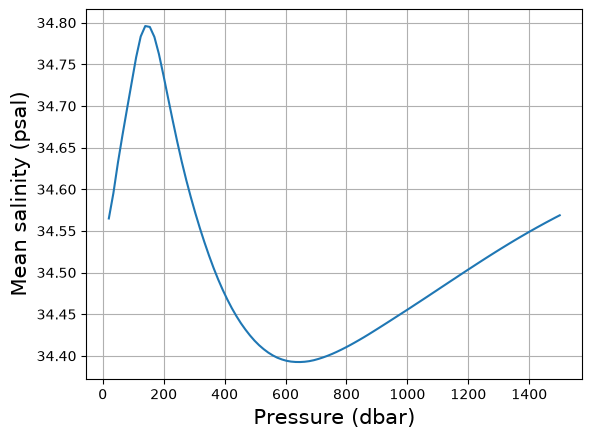

In [18]:
plt.clf()
plt.grid(True)
plt.plot(pressure, psal.mean(1))
plt.xlabel("Pressure (dbar)", size=15)
plt.ylabel("Mean salinity (psal)", size=15)

The depth calculations done by exhaustive enumeration are somewhat expensive so we subset the data for speed.

In [19]:
ii = np.random.choice(np.arange(temp.shape[1]), 5000, replace=False)
tempx = temp[:, ii]
psalx = psal[:, ii]
latx = lat[ii]
lonx = lon[ii]
dayx = day[ii]

Calculate the spatial depth of vector v relative to all columns of x.

In [20]:
def sdepth(v, x):
    p, n = x.shape
    z = x - v[:, None]
    zn = np.sqrt((z**2).sum(0))
    zn[np.abs(zn) < 1e-12] = np.inf
    z /= zn
    u = z.mean(1)
    return 1 - np.sqrt(np.sum(u**2))

Calculate the L2 depth of vector v relative to all columns of x.

In [21]:
def l2depth(v, x):
    p, n = x.shape
    z = x - v[:, None]
    zn = np.sqrt((z**2).sum(0))
    d = zn.mean()
    return 1e6 / (1 + d)

Estimate the band depth of vector v relative to all columns of x, using 500 random draws to estimate the band depth.

In [22]:
def bdepth(v, x, m=500):
    p, n = x.shape
    t = 0.0
    for k in range(m):
        ii = np.random.choice(n, 3, replace=False)
        z = x[:, ii]
        mn = z.min(1)
        mx = z.max(1)
        t += np.mean((v >= mn) & (v <= mx))
    t /= m
    return t

Calculate the depth of every column of 'x' relative to the other columns, using 'dfun' as the depth function.

In [23]:
def depths(x, dfun, progress=False):
    p, n = x.shape
    d = np.zeros(n)
    for i in range(n):
        if progress and (i % 200 == 0):
            print(i, end="", flush=True)
            print(".", end="", flush=True)
        d[i] = dfun(x[:, i], x)
    if progress:
        print("done", flush=True)
    return d

The function 'depth_cut' partitions the depth values into bins based on quantiles of the depth statistics, and plots a small random selection of profiles from each bin.  The arguments to this function are as follows:

* 'dpt' is a vector of depths 
* 'profiles' is an array of profiles (each column is a profile)
* 'q' is the number of bins into which the profiles are partitioned 
* 'pressure' is the pressures at which the profiles are recorded
* 'ylab' is a label for the vertical axis of the plot

In [24]:
def depth_cut(dpt, profiles, q, pressure, ylab):
    dpq = pd.qcut(dpt, q)
    for (i,iv) in enumerate(dpq.categories):
        ii = np.flatnonzero(dpq == iv)
        jj = np.random.choice(ii, 10)

        plt.clf()
        plt.figure(figsize=(6.4,4.8))
        plt.grid(True)
        plt.title("Depth quantile %d %s" % (i + 1, str(iv)))
        for j in jj:
            plt.plot(pressure, profiles[:, j], "-", color="grey")
        if ylab == "Temperature":
            plt.ylim(-5, 35)
        else:
            plt.ylim(32, 37)
        plt.ylabel(ylab, size=15)
        plt.xlabel("Pressure", size=15)
        plt.show()

In [25]:
dp_temp = depths(tempx, sdepth, progress=True)
dp_psal = depths(psalx, sdepth, progress=True)

0.200.400.600.800.1000.1200.1400.1600.1800.2000.2200.2400.2600.2800.3000.3200.3400.3600.3800.4000.4200.4400.4600.4800.done
0.200.400.600.800.1000.1200.1400.1600.1800.2000.2200.2400.2600.2800.3000.3200.3400.3600.3800.4000.4200.4400.4600.4800.done


Visualize the profiles as arranged according to their depth values.

<Figure size 640x480 with 0 Axes>

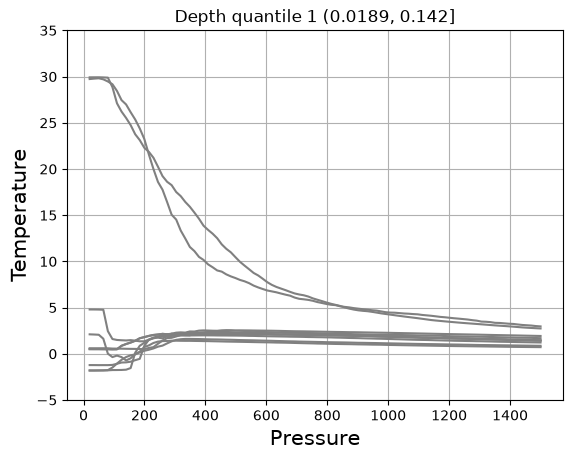

<Figure size 640x480 with 0 Axes>

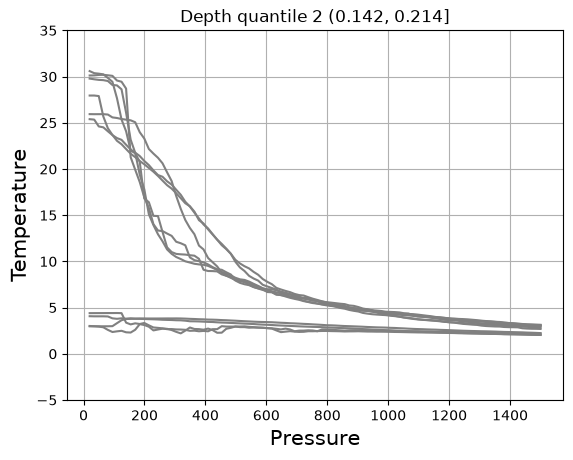

<Figure size 640x480 with 0 Axes>

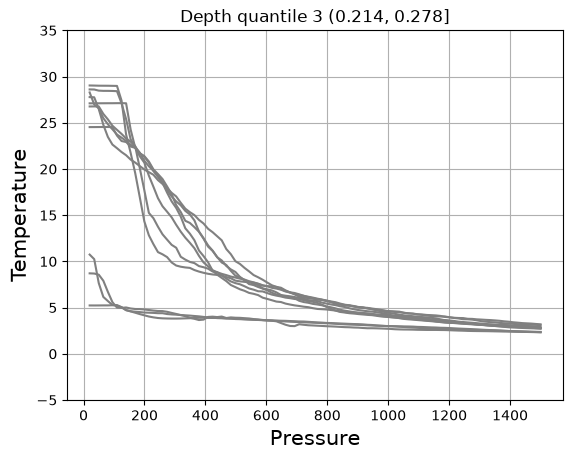

<Figure size 640x480 with 0 Axes>

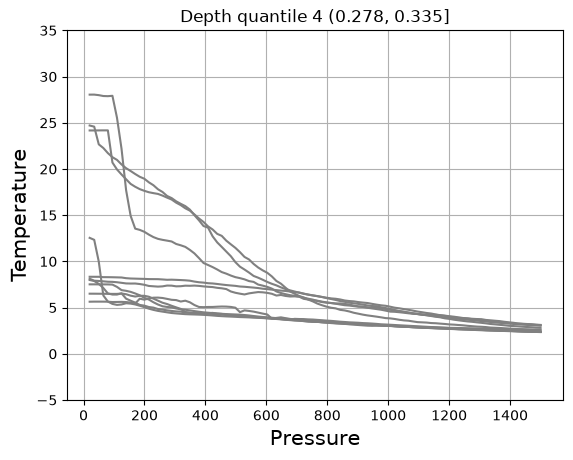

<Figure size 640x480 with 0 Axes>

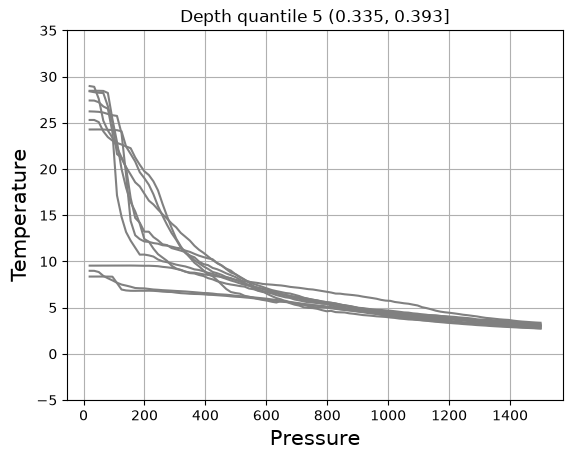

<Figure size 640x480 with 0 Axes>

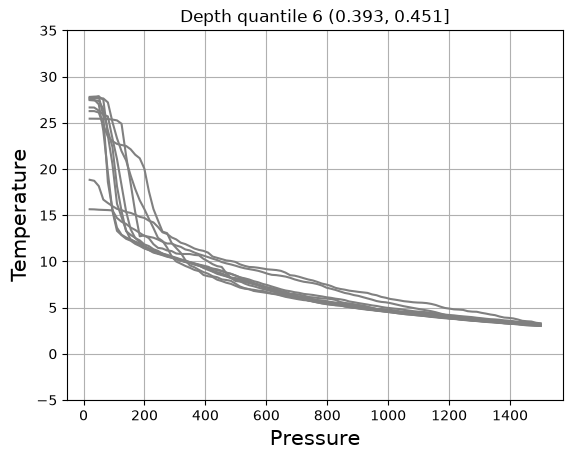

<Figure size 640x480 with 0 Axes>

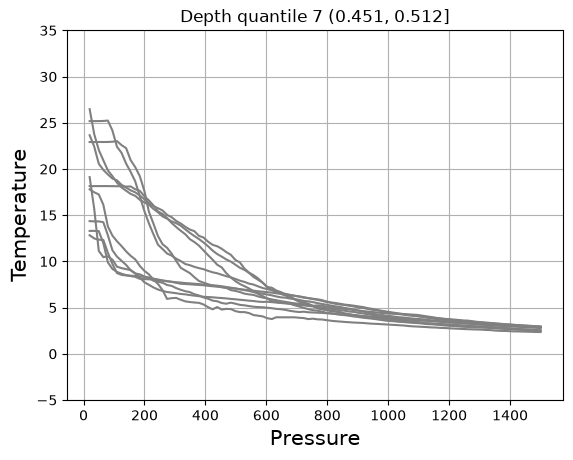

<Figure size 640x480 with 0 Axes>

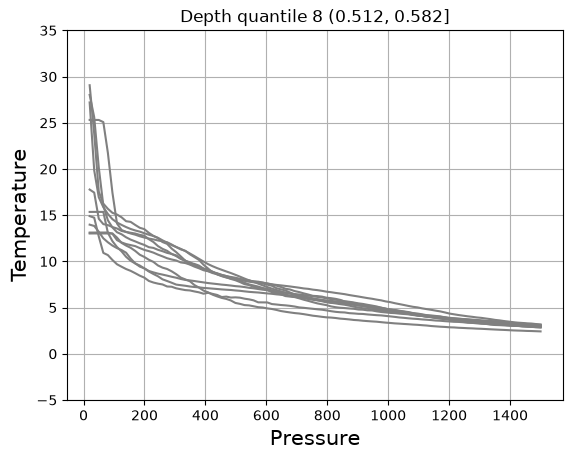

<Figure size 640x480 with 0 Axes>

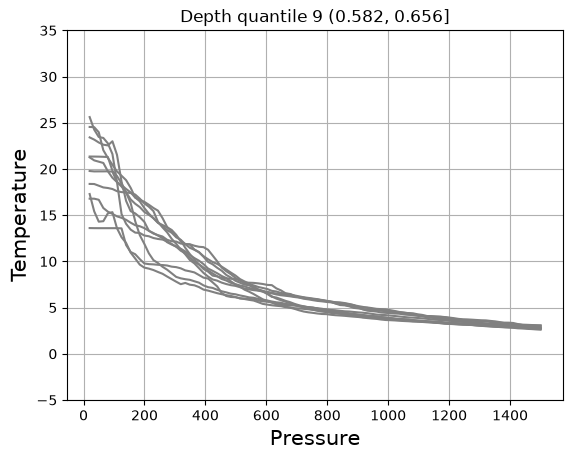

<Figure size 640x480 with 0 Axes>

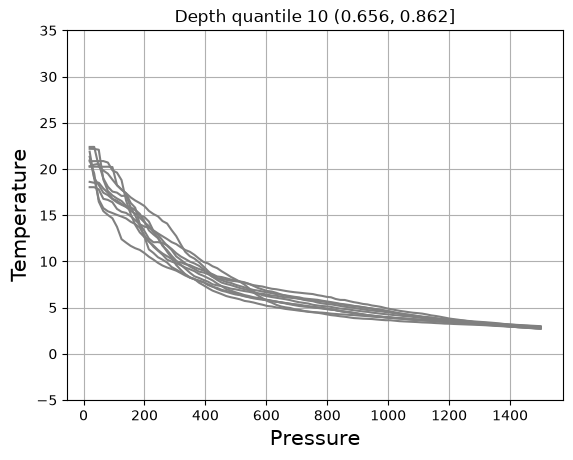

In [26]:
q = 10
depth_cut(dp_temp, tempx, q, pressure, "Temperature")

<Figure size 640x480 with 0 Axes>

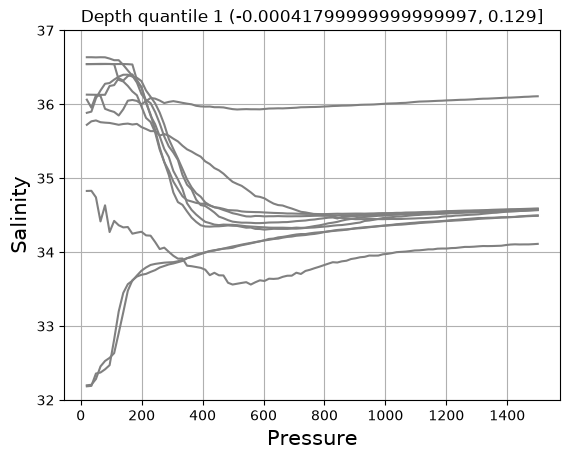

<Figure size 640x480 with 0 Axes>

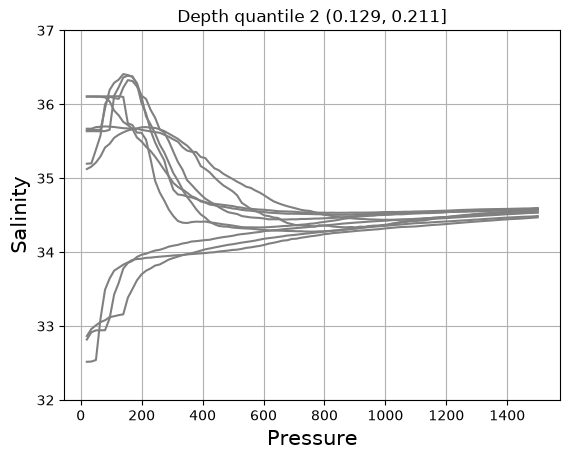

<Figure size 640x480 with 0 Axes>

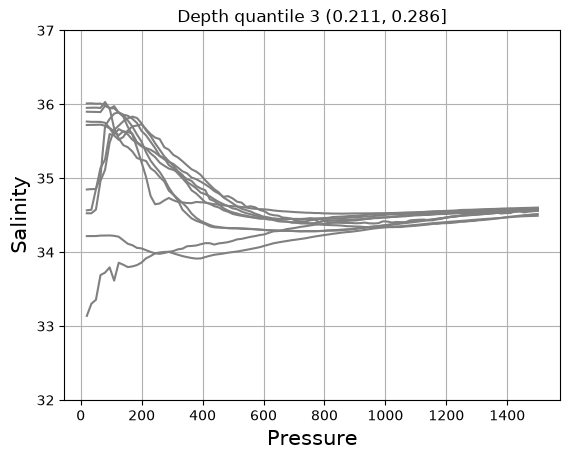

<Figure size 640x480 with 0 Axes>

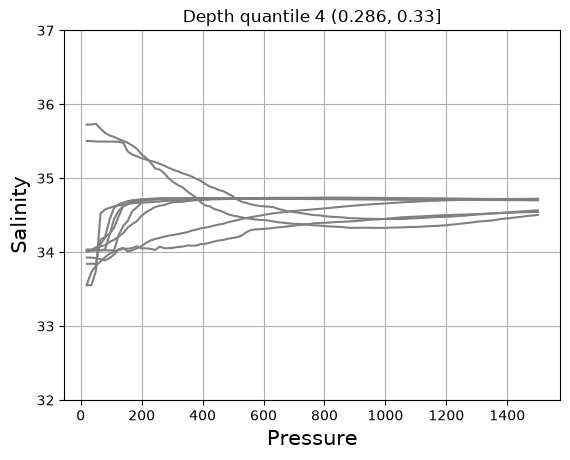

<Figure size 640x480 with 0 Axes>

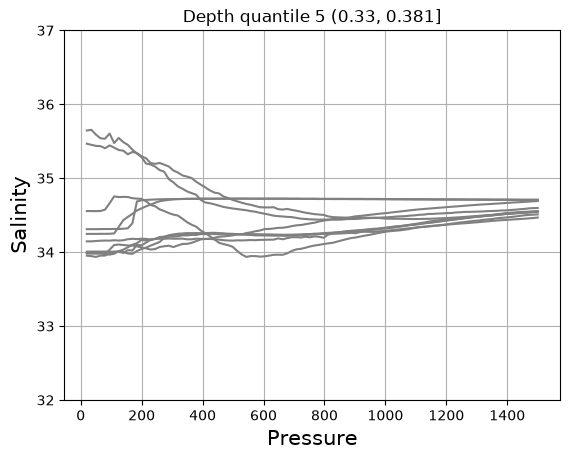

<Figure size 640x480 with 0 Axes>

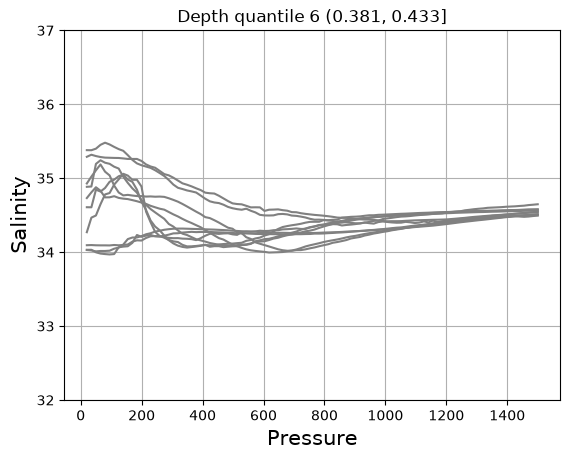

<Figure size 640x480 with 0 Axes>

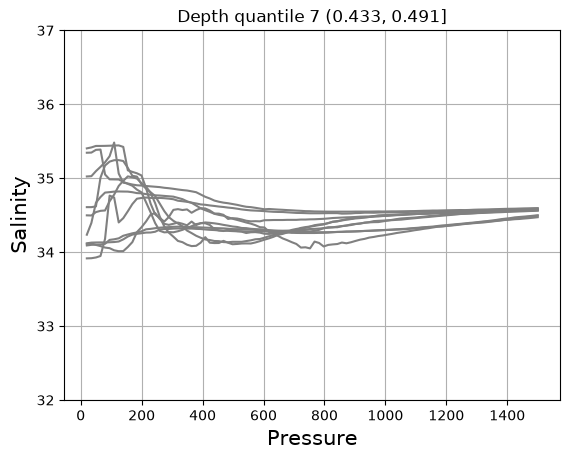

<Figure size 640x480 with 0 Axes>

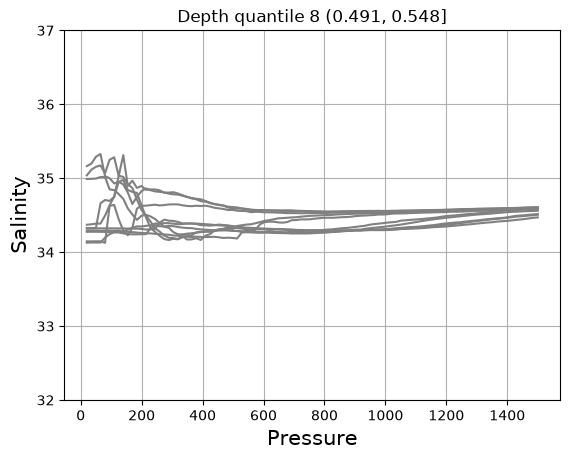

<Figure size 640x480 with 0 Axes>

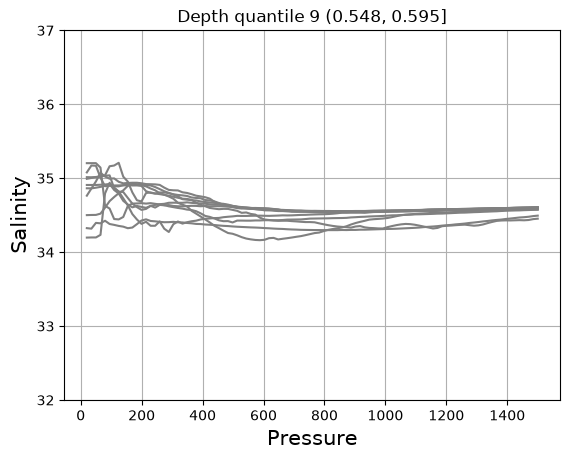

<Figure size 640x480 with 0 Axes>

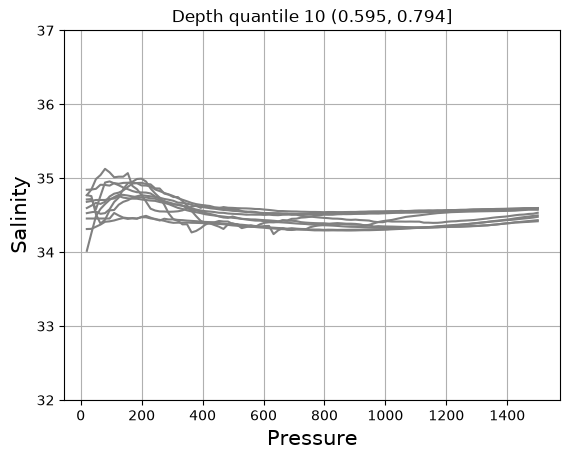

In [27]:
depth_cut(dp_psal, psalx, q, pressure, "Salinity")

The function 'plot_depth_map' plots the profile locations on a map, indicating which are the most shallow and which are the most deep.

In [28]:
def plot_depth_map(dp, title, lonx, latx):
    plt.clf()
    plt.figure(figsize=(8, 7.25))
    ax = plt.axes([0.05, 0.05, 0.84, 0.88], projection=ccrs.PlateCarree(central_longitude=180))
    ax.coastlines()
    ax.set_extent([115, 290, -70, 60])

    qq = np.argsort(np.argsort(dp)) / len(dp)
    ii = np.flatnonzero(qq < 0.1)
    plt.scatter(lonx[ii], latx[ii], s=8, color="blue", label="shallow",
                transform=ccrs.Geodetic())
    ii = np.flatnonzero(qq > 0.9)
    plt.scatter(lonx[ii], latx[ii], s=8, color="red", label="deep",
                transform=ccrs.Geodetic())

    ha,lb = plt.gca().get_legend_handles_labels()
    leg = plt.figlegend(ha, lb, loc="center right", handletextpad=0.01)
    leg.draw_frame(False)

    plt.title(title)
    plt.show()

<Figure size 640x480 with 0 Axes>

/Users/mmcanear/Projects/PhD_Courses/STAT604/case_studies/.venv/lib/python3.14/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


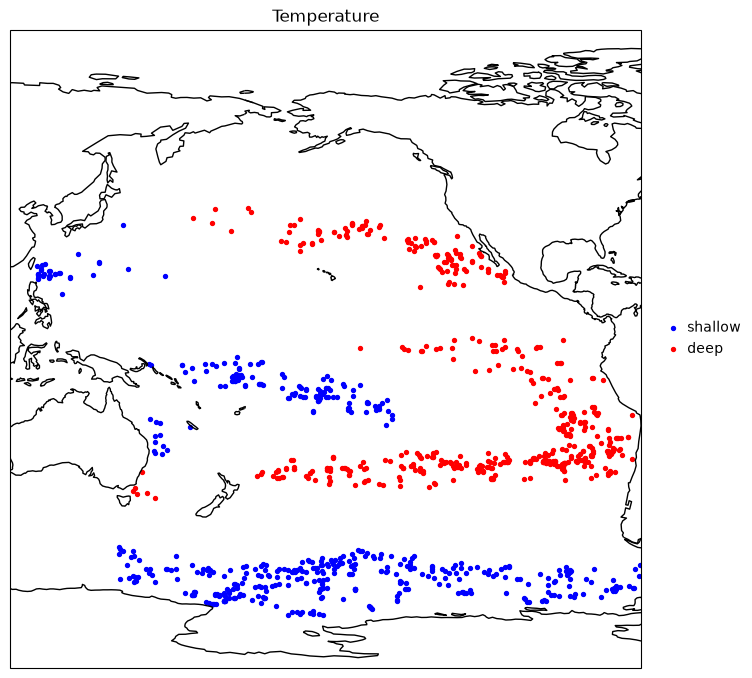

In [29]:
plot_depth_map(dp_temp, "Temperature", lonx, latx)

<Figure size 640x480 with 0 Axes>

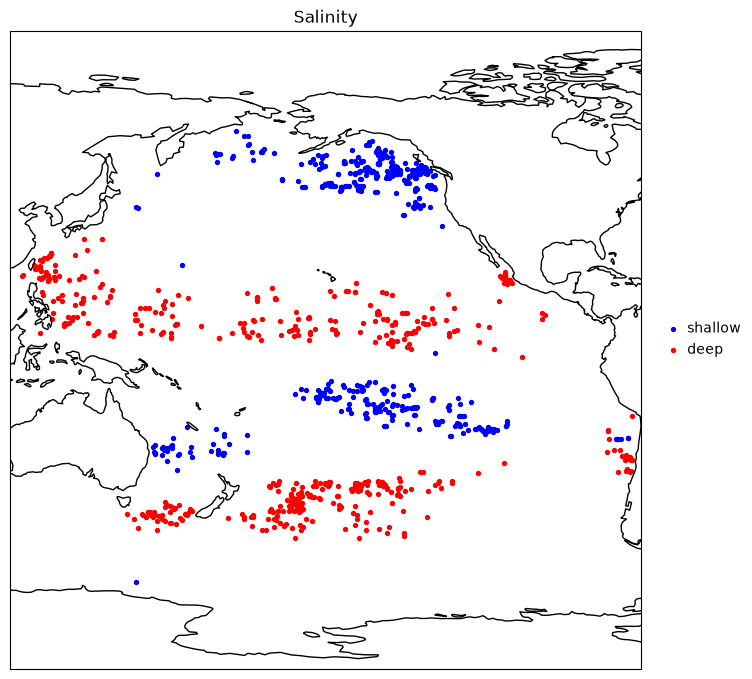

In [30]:
plot_depth_map(dp_psal, "Salinity", lonx, latx)

## Analysis as parameterized curves

The columns of 'temp' and 'psal' are paired (they are collected at the same location and time). The following [phase space](https://en.wikipedia.org/wiki/Phase_space) plot shows the relationship between temperature and salinity for a random selection of profiles.  The dot shows which end of the curve corresponds to the surface of the ocean.

Text(0, 0.5, 'Salinity')

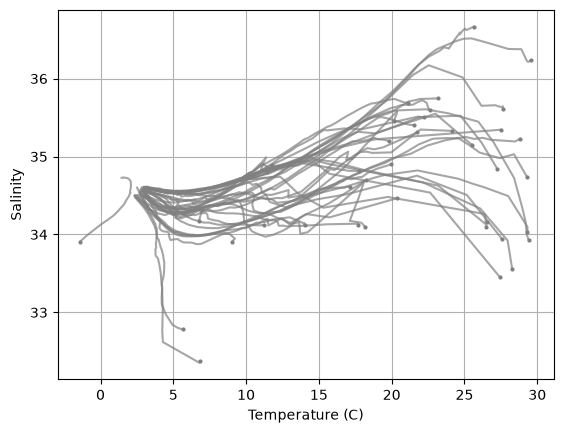

In [31]:
for j in range(40):
    i = np.random.choice(temp.shape[1])
    plt.plot(temp[0:1, i], psal[0:1, i], "o", color="grey", ms=2)
    plt.plot(temp[:, i], psal[:, i], color="grey", alpha=0.7)
plt.grid(True)
plt.xlabel("Temperature (C)")
plt.ylabel("Salinity")

[This paper](https://vis.cs.ucdavis.edu/vis2014papers/TVCG/papers/2654_20tvcg12-mirzargar-2346455.pdf) proposes some depth approaches for parametric curves.  They use a version of band depth adapted to the setting of parametric curves in the plane.  Below is a sketch-based implementation of this procedure that uses random selections of points for computational speed.

In [32]:
from scipy.spatial import Delaunay

def sketch_bdepth_pcurve(nrep=10000):

    rng = np.random.default_rng()
    P = np.zeros((temp.shape[1], nrep))

    for k in range(nrep):

        # Choose a time at random
        ii = rng.integers(low=0, high=100)

        # Choose three curves at random
        jj = rng.choice(temp.shape[1], size=3)

        # These points define a triangle in the plane.
        # Jitter a bit to avoid degeneracy
        x = temp[ii, jj]
        y = psal[ii, jj]
        Q = np.vstack((x, y)).T + 0.01 * np.random.normal(size=(3, 2))

        # Test whether every curve falls inside the given triangle
        R = np.vstack((temp[ii, :], psal[ii, :])).T
        P[:, k] = Delaunay(Q).find_simplex(R) >= 0

    # The depth is the proportion of the time that the inclusion holds.
    dp = P.mean(1)

    return dp

Below we show that using 5000 points to estimate the depth is fairly stable.

Text(0, 0.5, 'Run 2')

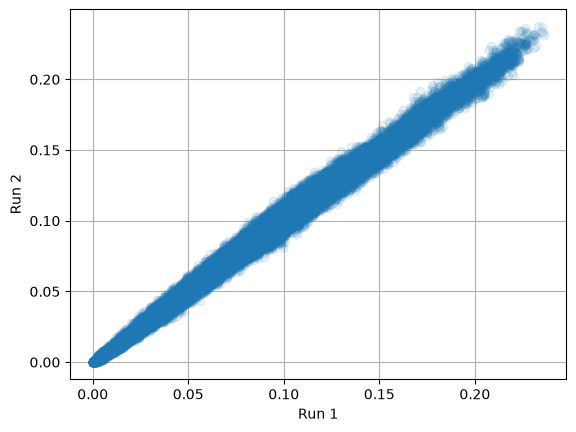

In [33]:
dp1 = sketch_bdepth_pcurve(5000)
dp2 = sketch_bdepth_pcurve(5000)
plt.grid(True)
plt.plot(dp1, dp2, "o", alpha=0.1)
plt.xlabel("Run 1")
plt.ylabel("Run 2")

The map below shows that the profiles identified as deep or shallow in the parameteric curve analysis are not very similar to what was identified in either the temperature-only or salinity-only analyses. 

<Figure size 640x480 with 0 Axes>

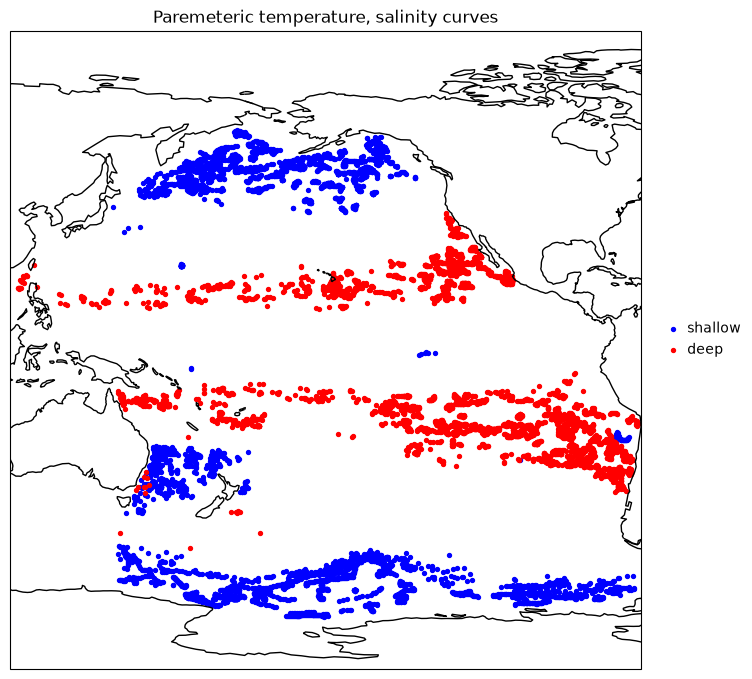

In [34]:
plot_depth_map(dp1, "Paremeteric temperature, salinity curves", lon, lat)

An alternative simpler (but perhaps less sophisticated) approach is to concatenate the temperature and salinity value, and use a more conventional depth measure such as the spatial depth.  Since temeperature and salinity are measured on different scales, we standardize the data before performing this analysis.

In [35]:
temp_scaled = tempx / np.linalg.norm(tempx, axis=0)
psal_scaled = psalx / np.linalg.norm(psalx, axis=0)
temp_psal = np.vstack((temp_scaled, psal_scaled))
dp_temp_psal = depths(temp_psal, sdepth, progress=True)

0.200.400.600.800.1000.1200.1400.1600.1800.2000.2200.2400.2600.2800.3000.3200.3400.3600.3800.4000.4200.4400.4600.4800.done


The results share some similarities to the parameteric curve approach, but there are some differences as well, e.g. what happens just east of Australia.

<Figure size 640x480 with 0 Axes>

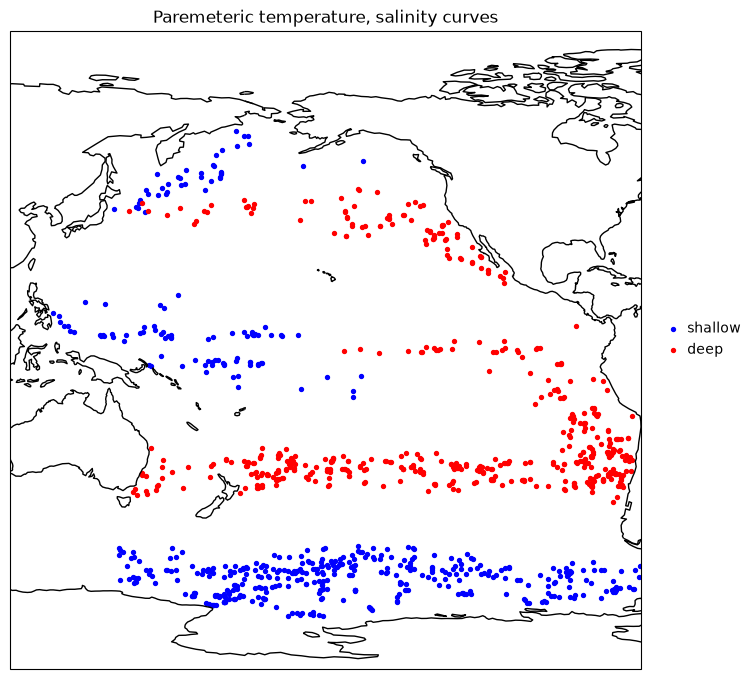

In [36]:
plot_depth_map(dp_temp_psal, "Paremeteric temperature, salinity curves", lonx, latx)